# Projeto 2, Sprint 1: Notebook 1
## Tempo de processamento de pagamentos PIX, Planilha 1 (antes da intervenção)

Este notebook responde às Questões 2 a 6 com os dados da Planilha 1, coletados antes da intervenção.

Variável analisada: tempo de processamento do pagamento PIX, em segundos (s). É o tempo entre o cliente confirmar o pagamento no aplicativo e aparecer a tela de comprovante.

Importa as bibliotecas que vamos usar.

In [1]:
import pandas as pd
import numpy as np
import math
import seaborn as sns
import matplotlib.pyplot as plt
import statsmodels.api as sm
from scipy.stats import norm
import pylab

%config InlineBackend.figure_format = 'retina'

Define o nome do arquivo da planilha (`arquivo`) e o nome da coluna que vai ser analisada (`coluna`).

In [2]:
arquivo = 'TEMPO PAGAMENTO PIX_planilha1_antes.xlsx'
coluna = 'Tempo_processamento_seg'

Lê a planilha e guarda os dados em `df`.

In [3]:
df = pd.read_excel(arquivo)
df

,Tempo_processamento_seg
0,3.01
1,3.47
2,3.67
3,3.68
4,3.75
...,...
95,6.54
96,6.57
97,6.61
98,6.84


Resumo dos dados com o `describe()` (quantidade, média, desvio padrão, mínimo, quartis e máximo).

In [4]:
df[coluna].describe().round(2)

count    100.00
mean       5.10
std        0.81
min        3.01
25%        4.53
50%        5.12
75%        5.64
max        6.87
Name: Tempo_processamento_seg, dtype: float64

A Planilha 1 tem 100 pagamentos PIX, com tempos entre 3,01 s e 6,87 s.

# Questão 2: Representação gráfica dos dados anteriores à intervenção

### a) Histograma

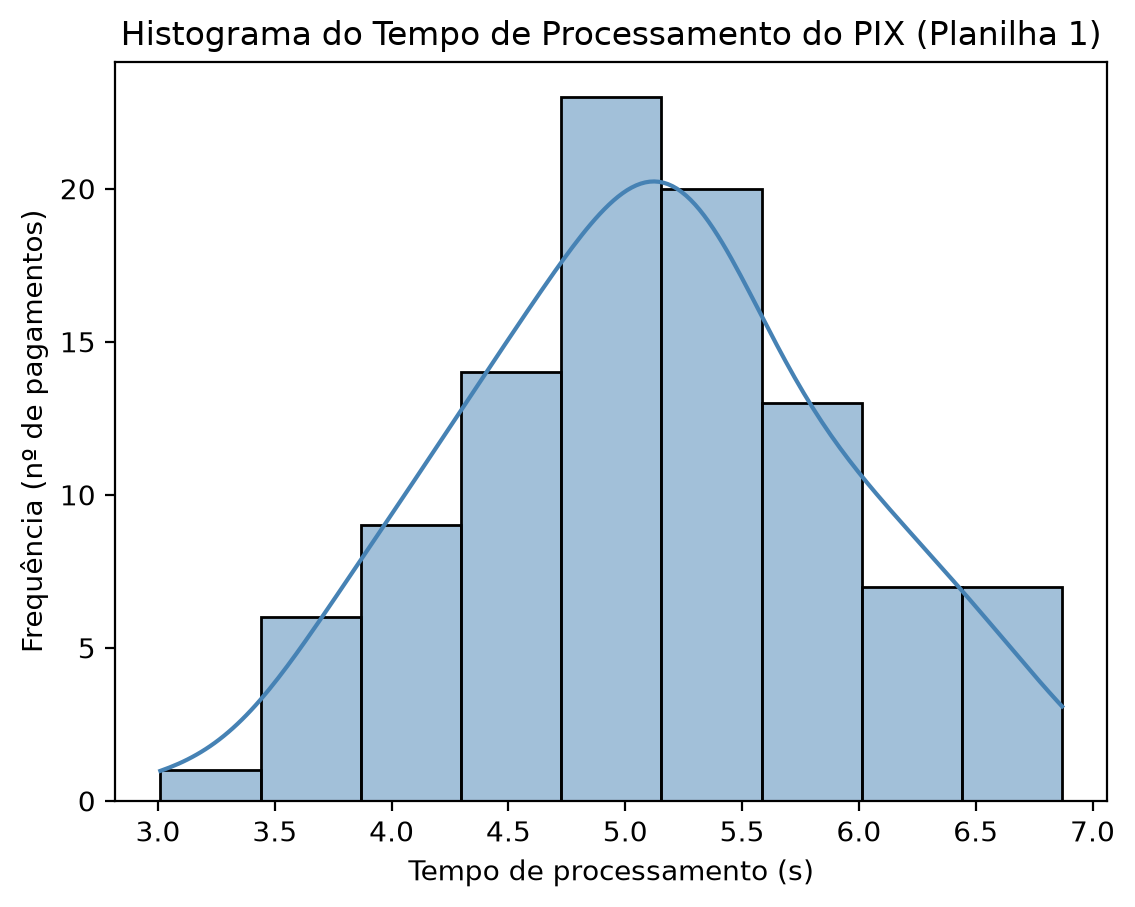

In [5]:
sns.histplot(data=df[coluna], kde=True, color='steelblue')
plt.title('Histograma do Tempo de Processamento do PIX (Planilha 1)')
plt.xlabel('Tempo de processamento (s)')
plt.ylabel('Frequência (nº de pagamentos)')
plt.show()

**Interpretação:** a maior parte dos pagamentos levou entre 4,5 s e 5,5 s para ser processada. O gráfico tem formato de sino, com as barras diminuindo dos dois lados, e quase nenhum pagamento ficou abaixo de 3,5 s.

### b) Boxplot

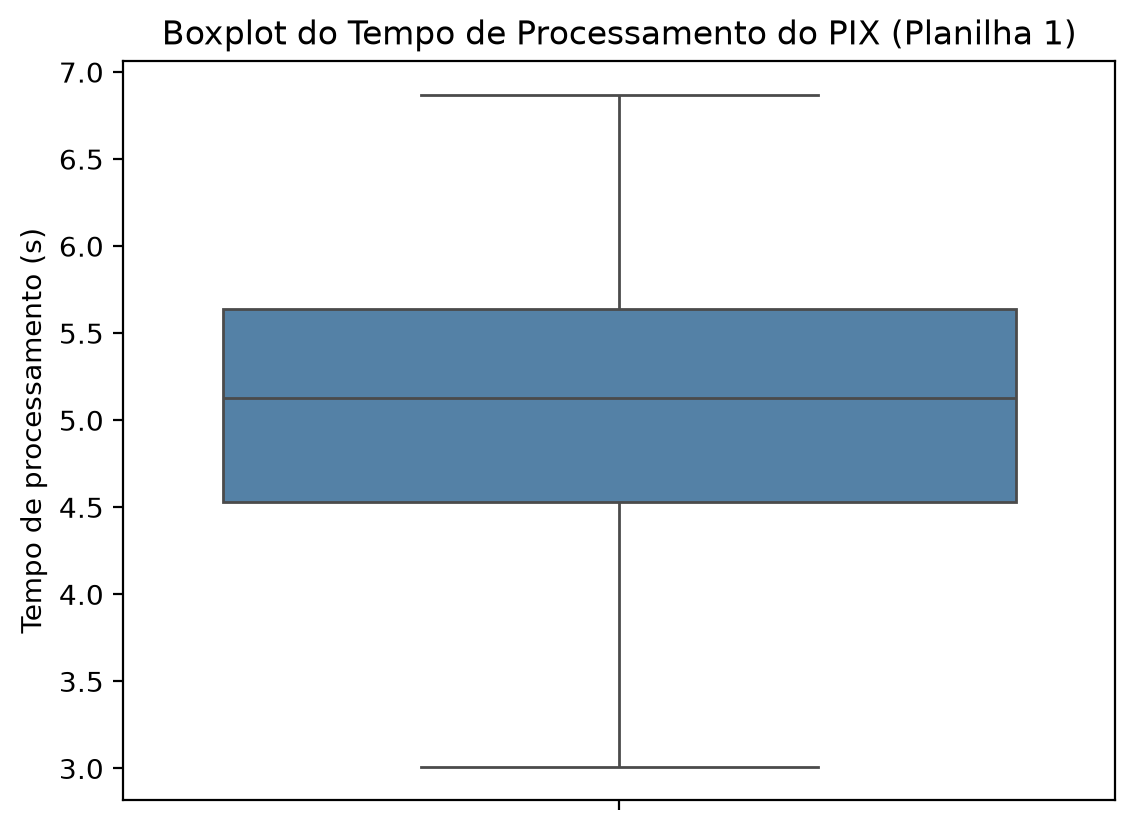

In [6]:
sns.boxplot(y=df[coluna], color='steelblue')
plt.title('Boxplot do Tempo de Processamento do PIX (Planilha 1)')
plt.ylabel('Tempo de processamento (s)')
plt.show()

**Interpretação:** a caixa (50% centrais dos dados) vai de mais ou menos 4,5 s até 5,6 s, com a mediana perto de 5,1 s. Não aparece nenhum ponto fora dos bigodes, então não tem outliers.

# Questão 3: Média e desvio padrão dos dados anteriores à intervenção

O `std()` do pandas calcula o desvio padrão amostral (divide por n - 1). Calculamos também a mediana, que vai ser usada na Questão 4.

In [7]:
media = df[coluna].mean()
dpad = df[coluna].std()
mediana = df[coluna].median()

print(f'Média: {media:.2f} s')
print(f'Desvio padrão: {dpad:.2f} s')
print(f'Mediana: {mediana:.2f} s')

Média: 5.10 s
Desvio padrão: 0.81 s
Mediana: 5.12 s


**Interpretação:** antes da intervenção, um pagamento PIX levava em média 5,10 s para ser processado, com desvio padrão de 0,81 s. Ou seja, a maioria dos pagamentos fica a menos de 1 s da média, mais ou menos entre 4,3 s e 5,9 s.

# Questão 4: Testes de normalidade

## a) Análise do histograma

### Pico único e proximidade com a média e a mediana

Histograma em densidade com a curva normal (usando a média e o desvio padrão da amostra) por cima, e linhas marcando a média e a mediana.

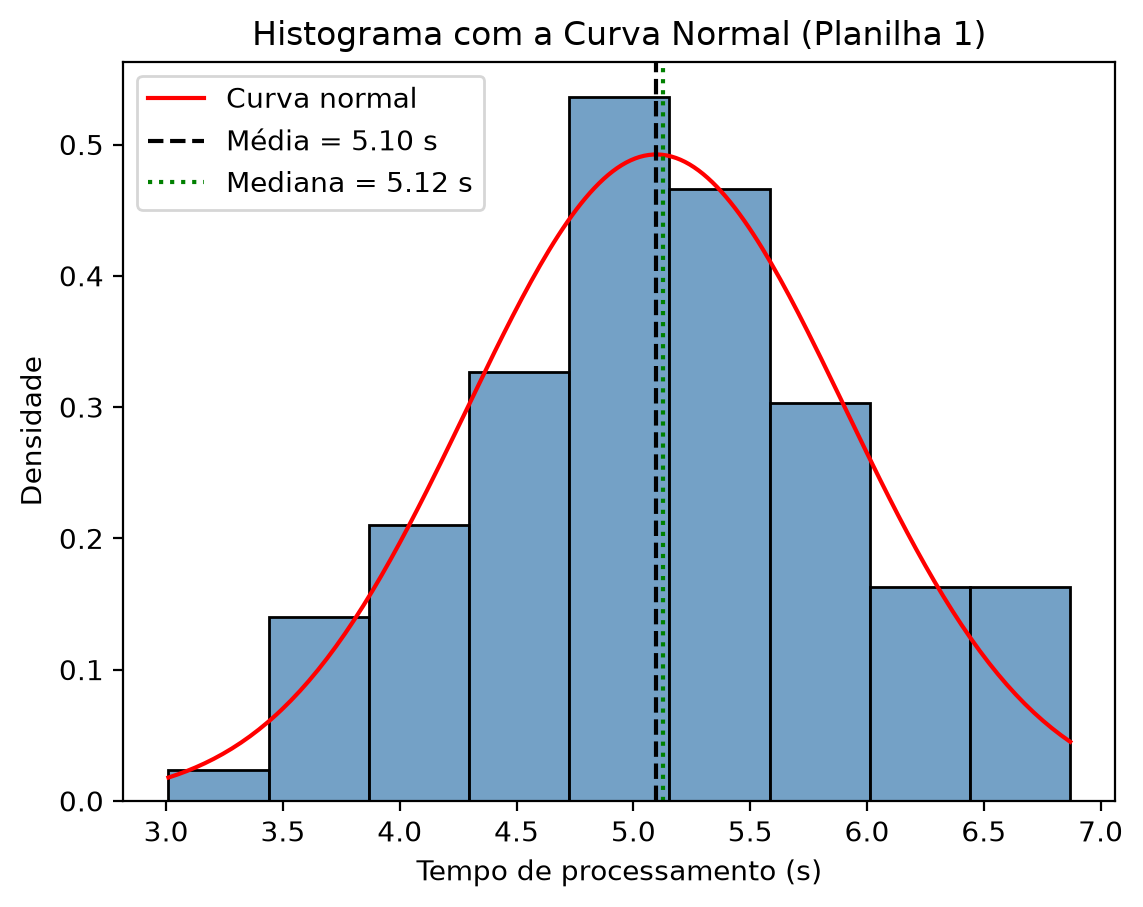

In [8]:
x = np.linspace(df[coluna].min(), df[coluna].max(), 200)

sns.histplot(data=df[coluna], stat='density', color='steelblue')
plt.plot(x, norm.pdf(x, loc=media, scale=dpad), color='red', label='Curva normal')
plt.axvline(media, color='black', linestyle='--', label=f'Média = {media:.2f} s')
plt.axvline(mediana, color='green', linestyle=':', label=f'Mediana = {mediana:.2f} s')
plt.title('Histograma com a Curva Normal (Planilha 1)')
plt.xlabel('Tempo de processamento (s)')
plt.ylabel('Densidade')
plt.legend()
plt.show()

Classe do histograma com maior frequência (o pico):

In [9]:
contagens, bordas = np.histogram(df[coluna], bins='auto')
i = contagens.argmax()
print(f'Pico: classe de {bordas[i]:.2f} s a {bordas[i+1]:.2f} s, com {contagens[i]} pagamentos')

Pico: classe de 4.73 s a 5.15 s, com 23 pagamentos


**Conclusão:** o histograma tem um único pico, na classe de 4,73 s a 5,15 s, e a média (5,10 s) e a mediana (5,12 s) estão as duas dentro dessa classe, praticamente no mesmo lugar. Isso é compatível com uma distribuição normal.

### Proporção de dados nos intervalos [μ - σ, μ + σ], [μ - 2σ, μ + 2σ] e [μ - 3σ, μ + 3σ]

Definindo os limites de cada intervalo:

In [10]:
limite_inf1dp = round(media - dpad, 2)
limite_inf2dp = round(media - 2*dpad, 2)
limite_inf3dp = round(media - 3*dpad, 2)
limite_sup1dp = round(media + dpad, 2)
limite_sup2dp = round(media + 2*dpad, 2)
limite_sup3dp = round(media + 3*dpad, 2)

print(f'[μ - σ, μ + σ]   = [{limite_inf1dp}, {limite_sup1dp}] s')
print(f'[μ - 2σ, μ + 2σ] = [{limite_inf2dp}, {limite_sup2dp}] s')
print(f'[μ - 3σ, μ + 3σ] = [{limite_inf3dp}, {limite_sup3dp}] s')

[μ - σ, μ + σ]   = [4.29, 5.91] s
[μ - 2σ, μ + 2σ] = [3.48, 6.72] s
[μ - 3σ, μ + 3σ] = [2.67, 7.53] s


Calculando a quantidade de dados em cada intervalo:

In [11]:
quantidade_1dp = sum(i >= limite_inf1dp and i <= limite_sup1dp for i in df[coluna].sort_values())
quantidade_2dp = sum(i >= limite_inf2dp and i <= limite_sup2dp for i in df[coluna].sort_values())
quantidade_3dp = sum(i >= limite_inf3dp and i <= limite_sup3dp for i in df[coluna].sort_values())

print('Quantidade em +- 1 desvio padrão:', quantidade_1dp)
print('Quantidade em +- 2 desvios padrão:', quantidade_2dp)
print('Quantidade em +- 3 desvios padrão:', quantidade_3dp)

Quantidade em +- 1 desvio padrão: 67
Quantidade em +- 2 desvios padrão: 96
Quantidade em +- 3 desvios padrão: 100


Calculando a proporção de dados em cada intervalo e comparando com a regra empírica (68%, 95% e 99,7%):

In [12]:
# Porcentagem entre +- 1, 2 e 3 desvios padrão
porcentagem1 = round((quantidade_1dp/len(df[coluna]))*100, 2)
porcentagem2 = round((quantidade_2dp/len(df[coluna]))*100, 2)
porcentagem3 = round((quantidade_3dp/len(df[coluna]))*100, 2)

pd.DataFrame({
    'Intervalo': ['μ ± 1σ', 'μ ± 2σ', 'μ ± 3σ'],
    'Limites (s)': [f'[{limite_inf1dp}, {limite_sup1dp}]', f'[{limite_inf2dp}, {limite_sup2dp}]', f'[{limite_inf3dp}, {limite_sup3dp}]'],
    'Quantidade': [quantidade_1dp, quantidade_2dp, quantidade_3dp],
    'Planilha 1 (%)': [porcentagem1, porcentagem2, porcentagem3],
    'Regra empírica (%)': [68, 95, 99.7]
})

,Intervalo,Limites (s),Quantidade,Planilha 1 (%),Regra empírica (%)
0,μ ± 1σ,"[4.29, 5.91]",67,67.0,68.0
1,μ ± 2σ,"[3.48, 6.72]",96,96.0,95.0
2,μ ± 3σ,"[2.67, 7.53]",100,100.0,99.7


**Conclusão:** as proporções da planilha (67%, 96% e 100%) ficaram bem próximas das esperadas para uma normal (68%, 95% e 99,7%). Então esse teste também indica que os dados são compatíveis com uma distribuição aproximadamente normal.

## b) Análise do boxplot (simetria dos quartis)

Numa distribuição simétrica, a distância entre Q1 e a mediana (Q2) é parecida com a distância entre Q2 e Q3, ou seja, Q2 - Q1 = Q3 - Q2.

In [13]:
Q1 = df[coluna].quantile(q=0.25)
Q2 = df[coluna].quantile(q=0.50)
Q3 = df[coluna].quantile(q=0.75)
AIQ = Q3 - Q1

print(f'Q1 = {Q1:.2f} s | Q2 = {Q2:.2f} s | Q3 = {Q3:.2f} s')
print(f'Q2 - Q1 = {Q2 - Q1:.2f} s')
print(f'Q3 - Q2 = {Q3 - Q2:.2f} s')
print(f'Diferença entre as distâncias = {abs((Q2 - Q1) - (Q3 - Q2)):.2f} s')

linf = Q1 - 1.5*AIQ
lsup = Q3 + 1.5*AIQ
print(f'Limites para outliers: linf = {linf:.2f} s e lsup = {lsup:.2f} s')
print('Quantidade de outliers:', len(df[(df[coluna] < linf) | (df[coluna] > lsup)]))

Q1 = 4.53 s | Q2 = 5.12 s | Q3 = 5.64 s
Q2 - Q1 = 0.59 s
Q3 - Q2 = 0.51 s
Diferença entre as distâncias = 0.08 s
Limites para outliers: linf = 2.87 s e lsup = 7.30 s
Quantidade de outliers: 0


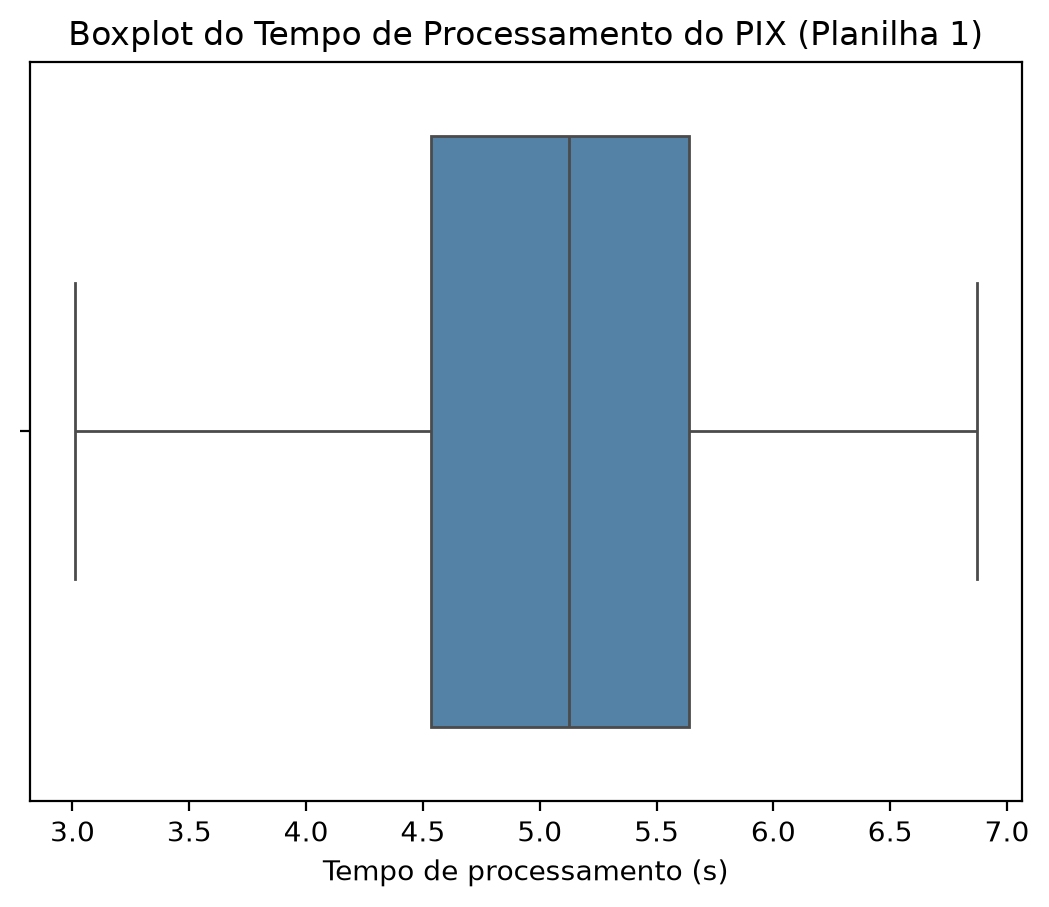

In [14]:
sns.boxplot(data=df[coluna], orient='h', color='steelblue')
plt.title('Boxplot do Tempo de Processamento do PIX (Planilha 1)')
plt.xlabel('Tempo de processamento (s)')
plt.show()

**Conclusão:** Q2 - Q1 = 0,59 s e Q3 - Q2 = 0,51 s, uma diferença de só 0,08 s (menos de 8% da amplitude interquartil, que é 1,11 s). A mediana fica quase no meio da caixa, os bigodes têm tamanhos parecidos e não tem outliers. O boxplot é aproximadamente simétrico, o que é compatível com uma distribuição normal.

## c) Diagrama Q-Q

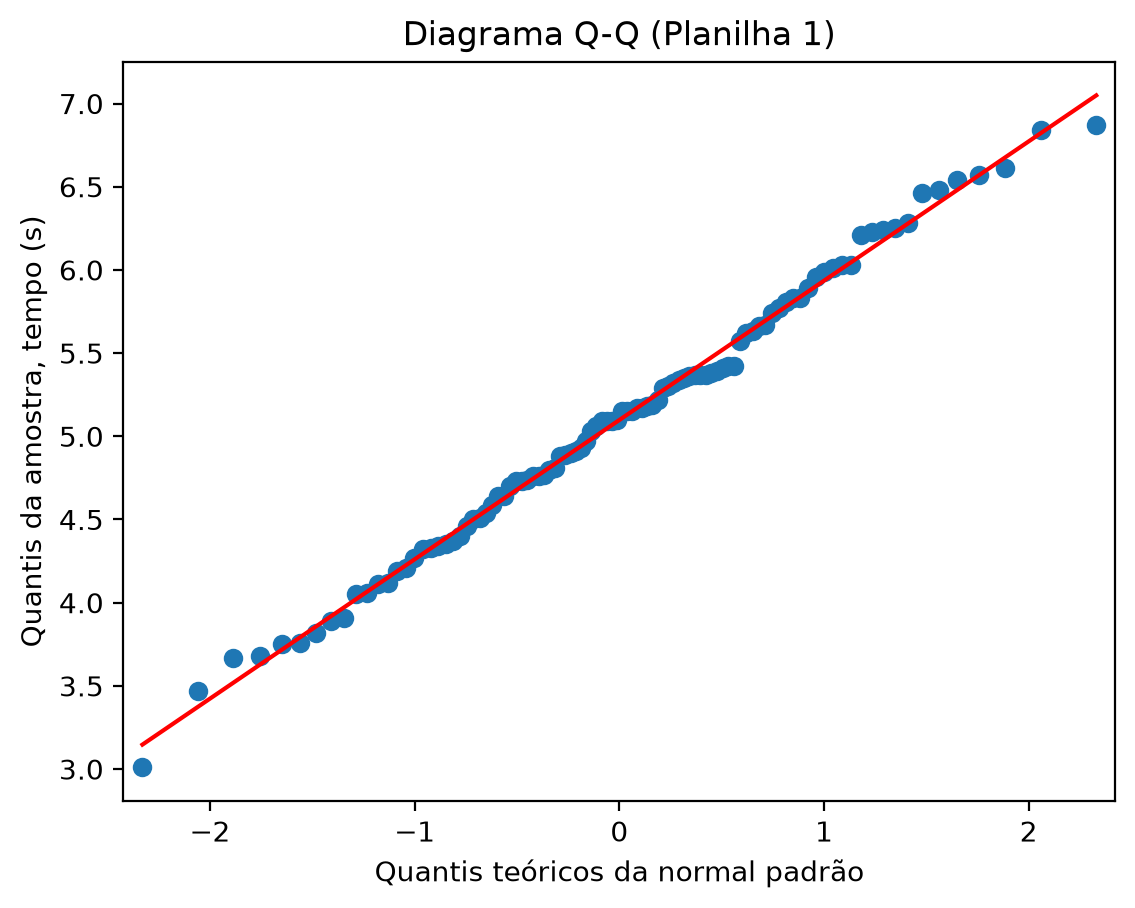

In [15]:
sm.qqplot(df[coluna], line='r')
plt.title('Diagrama Q-Q (Planilha 1)')
plt.ylabel('Quantis da amostra, tempo (s)')
plt.xlabel('Quantis teóricos da normal padrão')
pylab.show()

**Conclusão:** os pontos ficam praticamente em cima da reta vermelha no gráfico todo, só com pequenos desvios nas pontas (o que é comum numa amostra de 100 dados). Como não aparece nenhuma curva, o diagrama Q-Q indica que os dados são compatíveis com uma distribuição normal.

### Conclusão geral da Questão 4

Os três testes (histograma, boxplot e diagrama Q-Q) apontam para o mesmo lado: o tempo de processamento do PIX na Planilha 1 pode ser tratado como uma distribuição aproximadamente normal, com média 5,10 s e desvio padrão 0,81 s. Por isso, nas Questões 5 e 6 usamos os comandos da distribuição normal (`norm`).

# Questão 5: Probabilidade em um intervalo

Intervalo escolhido: [2 s, 4 s], que é a faixa em que ficam os pagamentos PIX dos aplicativos de banco mais bem avaliados (valor de referência da Questão 1).

Nos comandos abaixo: `loc` = média e `scale` = desvio padrão.

In [16]:
# P(2 <= x <= 4)
a = 2
b = 4
prob_ab = (norm.cdf(b, loc=media, scale=dpad) - norm.cdf(a, loc=media, scale=dpad)).round(4)
print(f'P({a} s <= X <= {b} s) = {prob_ab} ({prob_ab*100:.2f}%)')

P(2 s <= X <= 4 s) = 0.0876 (8.76%)


De complemento, a probabilidade de um pagamento passar do limite de tolerância de 5 s:

In [17]:
# P(x > 5)
prob_acima5 = norm.sf(5, loc=media, scale=dpad).round(4)
print(f'P(X > 5 s) = {prob_acima5} ({prob_acima5*100:.2f}%)')

P(X > 5 s) = 0.5481 (54.81%)


**Interpretação:** pelo modelo normal, a chance de um pagamento PIX ser processado entre 2 s e 4 s é de só 8,76%. Ou seja, menos de 1 em cada 10 pagamentos do nosso aplicativo fica no mesmo nível dos melhores bancos. E 54,81% dos pagamentos passam de 5 s, que é o ponto em que o cliente acha que o aplicativo travou.

# Questão 6: Valores máximos e mínimos que limitam determinados intervalos

### a) Valor máximo para estar entre os 20% menores valores
Queremos o valor x em que $P(X \le x) = 0{,}20$.

In [18]:
# P(x <= a) = 0,20  Valor de x para os 20% menores
valor_20_menores = norm.ppf(0.20, loc=media, scale=dpad).round(2)
print(f'Valor máximo dos 20% menores tempos: {valor_20_menores} s')

Valor máximo dos 20% menores tempos: 4.42 s


**Interpretação:** os 20% dos pagamentos PIX processados mais rápido levaram no máximo 4,42 s. Mesmo esse grupo, que é o mais rápido, ainda fica acima da faixa de referência do mercado (2 s a 4 s).

### b) Valor mínimo para estar entre os 30% maiores valores
Como o `norm.ppf` trabalha com a probabilidade acumulada, procurar os 30% maiores é o mesmo que procurar o valor que deixa 70% dos dados abaixo dele: $P(X \ge x) = 0{,}30$ é o mesmo que $P(X \le x) = 0{,}70$.

In [19]:
# P(x >= a) = 0,30  Valor de x para os 30% maiores
# Como usa-se a f.d.p. acumulada, procuramos os 70% menores
valor_30_maiores = norm.ppf(0.70, loc=media, scale=dpad).round(2)
print(f'Valor mínimo dos 30% maiores tempos: {valor_30_maiores} s')

Valor mínimo dos 30% maiores tempos: 5.52 s


**Interpretação:** os 30% dos pagamentos PIX mais lentos levaram pelo menos 5,52 s para serem processados, ou seja, todos acima do limite de tolerância de 5 s. É nesse grupo que estão os pagamentos com mais chance de gerar reclamação ou fazer o cliente pagar de novo.